# Reproducible model script

The code in this notebook comes from a standardised script used to train, test and extract evaluation metrics for the `squeezenet1_1` pretrained Neural Network. Mone information on limitations and background can be found in `\Jonty > script`.

### NOTE TO SELF
Importantly, we want to use only 90% of total data in this script, we will then use held-out data in final stage of model learning regime tuning and testing etc.

We thus will need to consider this before handing out.

In [1]:
import kagglehub

from pathlib import Path
from fastai.vision.all import *

from sklearn.model_selection import train_test_split
from collections import Counter

import torch

import matplotlib.pyplot as plt
import zipfile
from contextlib import redirect_stdout
from google.colab import files as colab_files

import shutil

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


In [2]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.

danielshanbalico_dog_emotion_path = kagglehub.dataset_download('danielshanbalico/dog-emotion')
print(danielshanbalico_dog_emotion_path)
mohitagarwal17_dog_img_path = kagglehub.dataset_download('mohitagarwal17/dog-img')
mohitagarwal17_dog_emotion_classifier_89_accuracy_other_default_1_path = kagglehub.model_download('mohitagarwal17/dog-emotion-classifier-89-accuracy/Other/default/1')

Using Colab cache for faster access to the 'dog-emotion' dataset.
/kaggle/input/dog-emotion
Using Colab cache for faster access to the 'dog-img' dataset.


In [3]:
searches = 'angry','happy','relaxed','sad'
path = Path(danielshanbalico_dog_emotion_path)

# Load the CSV containing the selected filenames
csv_url = "https://raw.githubusercontent.com/Sincanator/Group-Sprint-2/refs/heads/main/Data/emotion_classifier_data_from_kaggle/development_split.csv"
df = pd.read_csv(csv_url)

# Create files list using only filenames in CSV
files = [path / filename for filename in df["filename"]]

print(f"Number of images in subset: {len(files)}")

Number of images in subset: 3600


In [4]:
# Create train test split
train_files, test_files = train_test_split(
    files,
    test_size=0.15,
    random_state=42,
    stratify=[f.parent.name for f in files] # <- Addition to notebook
    )

print(len(train_files))
print(len(test_files))

# Checking the class distribution in data split
print("Training:", Counter(f.parent.name for f in train_files))
print("Testing:", Counter(f.parent.name for f in test_files))

3060
540
Training: Counter({'relaxed': 765, 'happy': 765, 'angry': 765, 'sad': 765})
Testing: Counter({'happy': 135, 'angry': 135, 'sad': 135, 'relaxed': 135})


## Learning
### Data Augmentation

The `aug_transforms` function is teeling us that if $T$ is one of these transformations, the class stays the same:
$$
y(T(x))=y(x)
$$
A transformation helps only when it preserves the meaning of the picture.

### Data Loaders

`bs=16` make batches of 16 images per step for training (step can be seen in the learning curve).

If the 3060 training images are spit into 20% validation and 80% training then we have (3060*0.8=) 2448 training images. This means that for `bs=16` we have $\frac{2448}{16}= 153$ training batches per epoch.

### Build the model

The `vision_learner()` funcrion builds the neural network model from the pretrained model using our data. We aren't specifying any weights so the function uses pretrained weights. The training that this fucntion does makes sure that the model outputs the 4 categories that we have.

#### Loss function

The model outputs four scores of how likely the input being in each class is. `softmax` converts them into probabilities.
For a dog with actual emotion $y$, the cross entropy loss is : $$L = -\ln (p_y)$$
where $p_y$ is the probability of the dog being assigned to the correct emotion.

The loss penalizes for being confidently wrong much more than being uncertain (eg. If the correct class gets probability $p_y=0.8$, then $L=-\ln(0.8)\approx 0.223.$
If it gets probability $p_y=0.1$, then $L=-\ln(0.1)\approx 2.303.$)

For a bach of 16 images, the mean loss is $$L_{\text{batch}}=\frac{1}{16} \sum_{i=1}^{16} -\ln(p_{i,y_i})$$
and `CrossEntorpyLossFlat()` applies this loss function for the classification.

#### Error rate

The `error_rate` calculates the fraction of input that is classified incorectly when testing the model. $$\text{error rate} = \frac{\text{number of incorrect predictions}}{\text{number of images}}.$$

Notice: $\text{Accuracy} = 1-\text{error rate}$.

So, the lower the error rate <-> the higher the accuracy.

#### Weight decay

`wd=0.1` represents the weight decay ie. for larger weights, it decays more. We do this so that the model doesn't rely on parameters that are particularly large. (it's like adding a penalty)
$$L_{\text{total}} = L_{\text{data}} + \frac{\lambda}{2} \lvert \lvert \theta \rvert \rvert ^2_2$$
where $L_{\text{data}}$ is the classification loss, $\theta$ represents the model weights and $\lambda$ controls the penalty. In our case $\lambda = 0.1$. This helps avoid overfitting.

#### Learning rate

`learn.lr_find()` runs a short  sequence to find a learning rate. It progressively raises the learning rate, observes the loss, and returns a suggested rate.

The learning rate is used to see how much to change the previous weights form a gradient descent run ie. $W_{ij} -LR \frac{\delta L}{\delta W_{ij}} \to W_{ij}$.
If the learning rate is too small, learning can be slow. If learning rate is too large, loss can increase (overfitting).

Notice that the vector of elements $\frac{\delta L}{\delta W_{ij}}$ tells us the direction that would reduce the loss.


### Conclusion

The following cell prepares a train/ validation split, standardises image sizes, augments only on the training set, creates batches, configures the pretrained `squeezenet1_1` model into outputting four classes and uses `learn.lr_find` to estimate a learning rate.


<div></div>

SuggestedLRs(valley=0.001737800776027143)


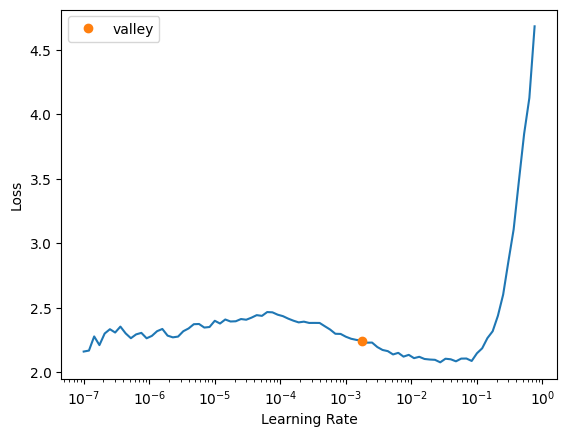

In [5]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), # input ImageBlock, answer CategoryBlock
    get_items=noop,
    splitter=RandomSplitter(valid_pct=0.2, seed=42), # generates random validation set 20% of train - the seed repeats the result
    get_y=parent_label, # gets labels from folder name
    item_tfms=[Resize(400, method='pad', pad_mode='reflection')], # resizes to 400 x 400 with padding using reflection padding mode. Done since squishing features may make harder to read expression
    batch_tfms=aug_transforms(mult=1.0, #overall strenght of these augmentations
                              do_flip=True,
                              flip_vert=False, #no upside down flips
                              max_rotate=15.0, #allows rotations up to 15 degrees
                              min_zoom=1.0,
                              max_zoom=1.1, #allow image to stay at original size or zoom in by 10%
                              max_lighting=0.2, # allows lighting changes
                              max_warp=0.1) # allows limited geometric distortion
    # augmentation done on the fly and in place rather than statically, changes for each training epoch to reduce overfitting
).dataloaders(train_files, bs=16) # batch size of 16 is changed from 56 since crahsed t4gpu usage limits, train data is of size 3600 * 0.85 * 0.8 = 2720 (2720 / 40 = 68)

learn = vision_learner(dls, #our dataset
                       squeezenet1_1, #pretrained model
                       loss_func=CrossEntropyLossFlat(), #loss function to calculate predictive power
                       metrics=error_rate, # performance metric => error rate = 1 - accuracy
                       wd=0.1).to_fp16() # using transfer learning from pretrained sqeezenet1_1 model
lr_suggestion = learn.lr_find() #tries a range of learning rates
print(lr_suggestion)
lr = lr_suggestion.valley

## Fine Tuning

What the following cell does: uses the learning rate defined in previous cell to train the model with it and plot the learning curve

### Adapting the pretrained model

`learn.fine_tune(4, base_lr=lr)` uses fastai fine tuning procedure.
Steps it takes:
1. Freezes most of the pretraained model's layers
2. Trains the head of the model - the head is the part that turns visual features into scores for each category. It does this for one epoch. The `fine_tune` function defaults as `freeze_epochs = 1`
3. Unfreezes the other laters and trains the full model for four more epochs.

`learn.fit_one_cycle(5, lr_max=slice(lr/100, lr))` continues doing training for five more epochs.
Combined with `fine_tune(4)` the code requests 10 epochs in total (one only head epoch, four full model epochs, five more full model epochs)
- `fit_one_cycle` changes the learning rate over the course of training.
- `slice(lr/100,lr)` represents the range of learning rates for the model's parameters. Usinf this range gives smaller lrs for earlier hidden layers and larger lr for later ones (including head). The idea is that the earlier layers already contain useful visual features so they need gentler changes, while the task specfic layers needs more adjustments.

Note: to see if those five extra epochs were helpful, we need to look at the validation loss rather than the training loss. If training loss continues to fall while validation loss stops falling or starts raising, that suggests that extra traing may be overfitting the model.

In our case we hsould educe the number of epochs!!

GPU available: Tesla T4
CUDA version: 13.0
Tesla T4


epoch,train_loss,valid_loss,error_rate,time
0,1.479858,0.932243,0.334967,00:25


epoch,train_loss,valid_loss,error_rate,time
0,1.049718,0.668293,0.258170,00:29
1,0.880528,0.698591,0.263072,00:28
2,0.714739,0.536222,0.210784,00:28
3,0.604908,0.507832,0.194444,00:28


epoch,train_loss,valid_loss,error_rate,time
0,0.697162,0.706932,0.299020,00:28
1,0.792856,0.692027,0.279412,00:28
2,0.690537,0.628104,0.227124,00:28
3,0.513608,0.485726,0.196078,00:28
4,0.405698,0.486699,0.196078,00:29


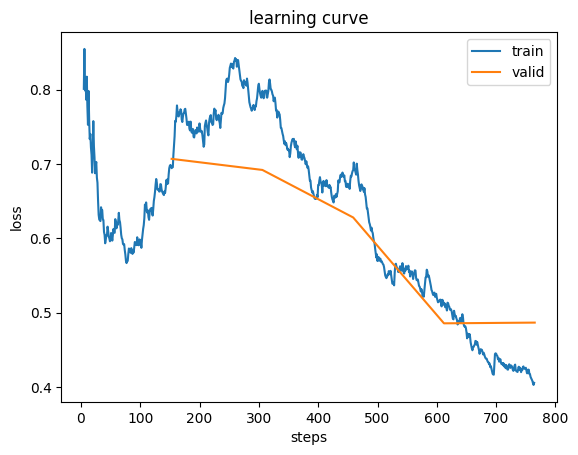

In [6]:
if torch.cuda.is_available():
    print("GPU available:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("No GPU available. Using CPU.")

print(torch.cuda.get_device_name(0))

learn.fine_tune(4, base_lr=lr) # finetune is built in to tune pretrained models, it uses a scheuled lr. for 4 epochs trains class head, then whole model for 1 epoch
learn.unfreeze() #this line is redundant since the previous line already unfreezes the model for its four full model epochs
learn.fit_one_cycle(5, lr_max=slice(lr/100, lr)) # five more epochs learning

plt.close('all')
learn.recorder.plot_loss()
plt.show()

In [7]:
test_dl = dls.test_dl(test_files, with_labels=True)
loss, err = learn.validate(dl=test_dl)
accuracy = (1-err)*100
print(f"Test Images: {len(test_files)}")
print(f"Correct Predictions: {round(accuracy*len(test_files)/100)}")
print(f"Incorrect Predictions: {len(test_files)-round(accuracy*len(test_files)/100)}")
print(f"Accuracy: {accuracy:.2f}%")

Test Images: 540
Correct Predictions: 443
Incorrect Predictions: 97
Accuracy: 82.04%


In [8]:
next(learn.model.parameters()).device

##############################
### PUT MODEL NAME IN PATH ###
##############################

save_path = Path('/content/dog_emotion_model_squeezenet1_1.pkl')

# Export the trained model
learn.cpu()
learn.export(save_path)

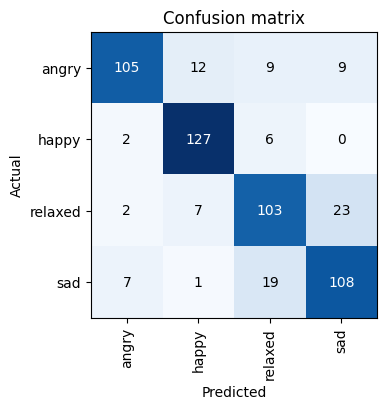

In [9]:
interp = ClassificationInterpretation.from_learner(
    learn,
    dl=test_dl)
interp.plot_confusion_matrix(figsize=(4,4))

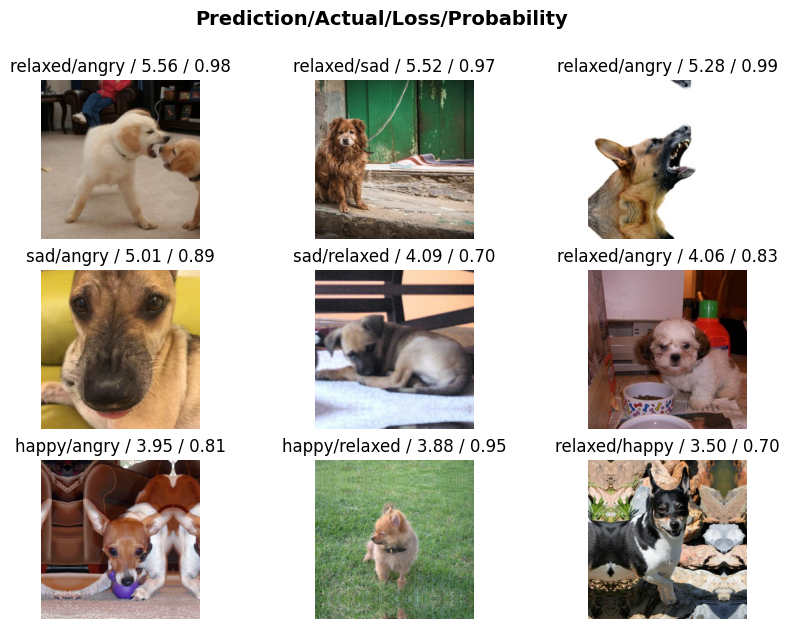

In [10]:
interp.plot_top_losses(9, figsize=(10,7))

In [11]:
interp.print_classification_report()

              precision    recall  f1-score   support

       angry       0.91      0.78      0.84       135
       happy       0.86      0.94      0.90       135
     relaxed       0.75      0.76      0.76       135
         sad       0.77      0.80      0.79       135

    accuracy                           0.82       540
   macro avg       0.82      0.82      0.82       540
weighted avg       0.82      0.82      0.82       540



results of form true | predicted


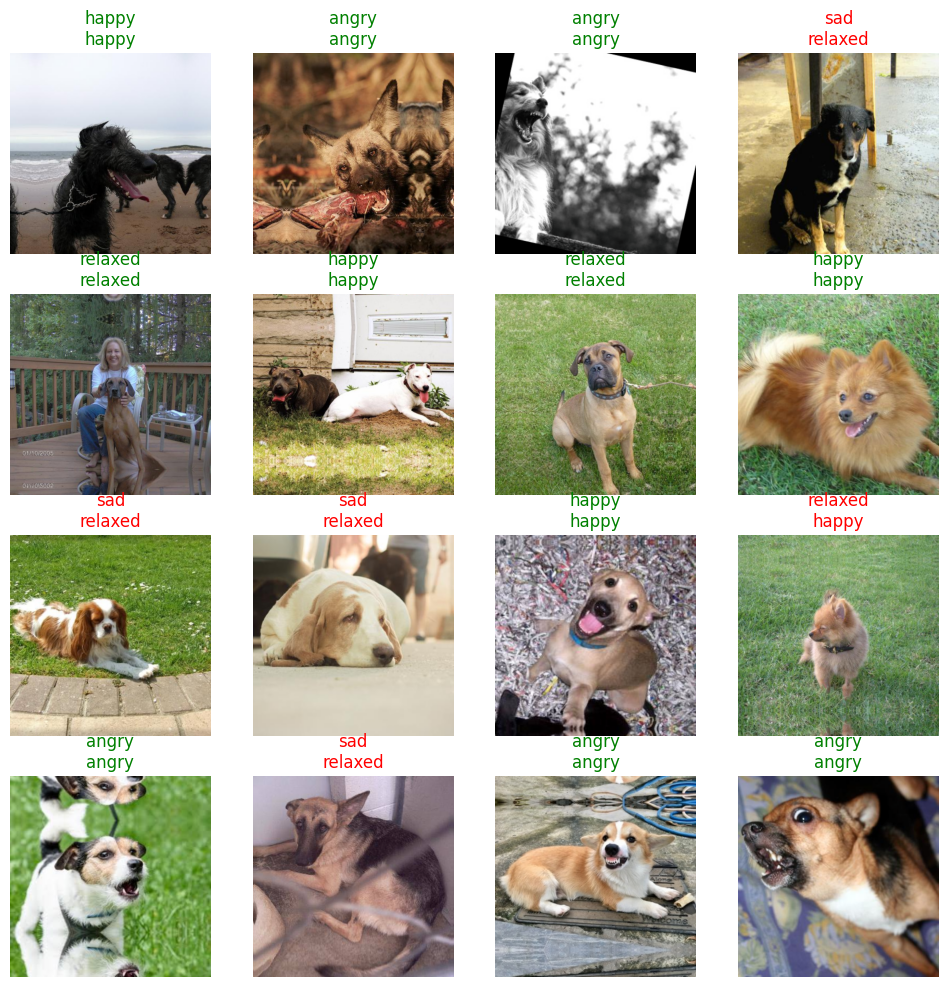

In [12]:
print(f'results of form true | predicted')
interp.show_results(idxs=list(range(16)))

In [13]:
# Create results folder

#############################
### CHANGE DIRECTORY NAME ###
#############################
results_dir = Path('/content/squeezenet1_1_results')
results_dir.mkdir(exist_ok=True)

# 1. Copy exported model into results folder
shutil.copy(save_path, results_dir / save_path.name)

# 2. Save confusion matrix
interp.plot_confusion_matrix(figsize=(4, 4))
plt.savefig(results_dir / 'confusion_matrix.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 3. Save top 9 losses
interp.plot_top_losses(9, figsize=(10, 7))
plt.savefig(results_dir / 'top_losses.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 4. Save classification report
with open(results_dir / 'classification_report.txt', 'w') as f:
    with redirect_stdout(f):
        interp.print_classification_report()

# 5. Save 16 example predictions
interp.show_results(idxs=list(range(16)))
plt.savefig(results_dir / 'example_predictions.png',
            bbox_inches='tight', dpi=200)
plt.close('all')

# 6. Create ZIP
zip_path = Path('/content/squeezenet1_1_results.zip')

with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for file in results_dir.iterdir():
        if file.is_file():
            zipf.write(file, arcname=file.name)

# 7. Download
colab_files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>